# 01.6 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/01-working-with-data/06-pandas-groupby-merge/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()

(541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")

541,910 rows → 392,693 after cleaning


## Exercise 1

In [3]:
per_invoice = sales.groupby(["Invoice", "Country"])["Revenue"].sum().reset_index()
aov = per_invoice.groupby("Country")["Revenue"].agg(invoices="size", avg_order_value="mean")
aov[aov["invoices"] >= 50].sort_values("avg_order_value", ascending=False).round(0).head(8)

,invoices,avg_order_value
Country,,
Netherlands,94,3037.0
Australia,57,2429.0
Switzerland,51,1107.0
EIRE,260,1020.0
Spain,90,684.0
Portugal,57,586.0
France,389,537.0
Germany,457,500.0


The Netherlands and Australia have far larger orders than the UK: a few wholesale buyers. Averaging per *row* instead of per *invoice* would have given a different and wrong answer.

## Exercise 2

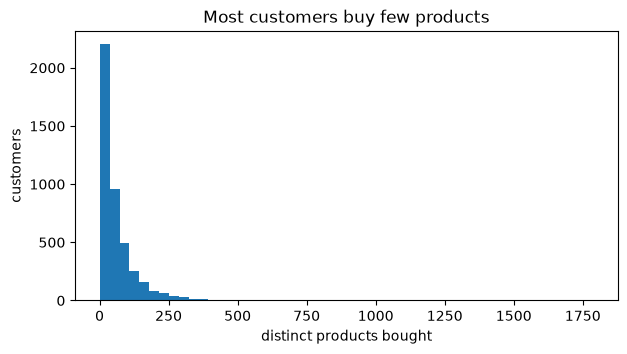

count    4338.0
mean       62.0
std        85.0
min         1.0
25%        16.0
50%        35.0
75%        77.0
max      1787.0
Name: StockCode, dtype: float64


In [4]:
import matplotlib.pyplot as plt
products_per_cust = sales.groupby("Customer ID")["StockCode"].nunique()
products_per_cust.plot.hist(bins=50, figsize=(7, 3.5))
plt.xlabel("distinct products bought"); plt.ylabel("customers"); plt.title("Most customers buy few products")
plt.show()
print(products_per_cust.describe().round(0))

Heavily right-skewed: the median customer bought about 40 distinct products, a handful bought over 1,000. You will meet this shape again and again; it is why medians and log scales exist (01.8).

## Exercise 3

In [5]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Sunday"]
heat = (sales.assign(weekday=sales["InvoiceDate"].dt.day_name(), hour=sales["InvoiceDate"].dt.hour)
             .pivot_table(index="weekday", columns="hour", values="Revenue", aggfunc="sum", fill_value=0)
             .reindex(days).round(0))
heat.loc[:, 8:16]

hour,8,9,10,11,12,13,14,15,16
weekday,,,,,,,,,
Monday,43343.0,123955.0,183627.0,160302.0,184573.0,225248.0,187624.0,140757.0,74536.0
Tuesday,72383.0,164257.0,294899.0,260913.0,245024.0,211515.0,160735.0,167304.0,90360.0
Wednesday,45770.0,122938.0,243347.0,201287.0,276036.0,231600.0,179091.0,160053.0,81464.0
Thursday,67844.0,134087.0,273577.0,170597.0,285466.0,196113.0,200940.0,229528.0,138245.0
Friday,52657.0,296377.0,182872.0,166547.0,229710.0,166968.0,159406.0,136864.0,43976.0
Sunday,0.0,779.0,80946.0,141532.0,152904.0,137281.0,104196.0,129054.0,38799.0


Weekday late mornings (10:00–13:00), peaking Thursday around noon. No Saturday row at all.

## Exercise 4

In [6]:
products = (sales.groupby("StockCode")["Description"]
                 .agg(lambda s: s.value_counts().index[0])
                 .rename("name").reset_index())
product_rev = sales.groupby("StockCode")["Revenue"].sum().reset_index()

merged = pd.merge(product_rev, products, on="StockCode", how="left", validate="one_to_one")
assert len(merged) == len(product_rev)
merged.sort_values("Revenue", ascending=False).head(5).round(0)

,StockCode,Revenue,name
2329,23843,168470.0,"PAPER CRAFT , LITTLE BIRDIE"
1218,22423,142265.0,REGENCY CAKESTAND 3 TIER
3349,85123A,100547.0,WHITE HANGING HEART T-LIGHT HOLDER
3343,85099B,85041.0,JUMBO BAG RED RETROSPOT
1927,23166,81417.0,MEDIUM CERAMIC TOP STORAGE JAR
